#**Kelompok The Luna**

Ketua Kelompok: Dian Fatonah (2215061115)

Anggota Kelompok:
1. Dini Canika Sumara (2215061026)
2. Safrina Fitriani (2255061015)

Asal: Universitas Lampung

# 1. Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files

In [2]:
seed = 404
np.random.seed(seed)
"Done"

'Done'

# 2. Gathering Data

In [3]:
# Load the dataset
url = "https://raw.githubusercontent.com/dianftnh/TheLuna_PeDas2025/main/Dataset/dataCarSale2021-2025.csv"

df = pd.read_csv(url)

print(df.head())

        waktu  DAIHATSU    HONDA  MITSUBISHI  SUZUKI   TOYOTA
0  2021-01-01    8993.0   7231.0      9108.0  6400.0  15474.0
1  2021-02-01    9412.0   6812.0      7567.0  4600.0  14645.0
2  2021-03-01   16770.0  11350.0     13088.0  8669.0  26034.0
3  2021-04-01   15861.0   8474.0     13820.0  8100.0  22618.0
4  2021-05-01    8310.0   5832.0     10160.0  5341.0  17361.0


# 3. Assesing Data

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   waktu       54 non-null     object 
 1   DAIHATSU    54 non-null     float64
 2   HONDA       54 non-null     float64
 3   MITSUBISHI  54 non-null     float64
 4   SUZUKI      54 non-null     float64
 5   TOYOTA      54 non-null     float64
dtypes: float64(5), object(1)
memory usage: 2.7+ KB


In [5]:
# Cek jumlah duplikat
# Harus dicek manual di Spreadsheetnya
duplikat = df.duplicated()
print(f"Jumlah baris duplikat: {duplikat.sum()}")

# Tampilkan contoh duplikat
df[duplikat]

Jumlah baris duplikat: 0


,waktu,DAIHATSU,HONDA,MITSUBISHI,SUZUKI,TOYOTA


In [6]:
#Memastikan Adanya Missing Value
df.isna().sum()

,0
waktu,0
DAIHATSU,0
HONDA,0
MITSUBISHI,0
SUZUKI,0
TOYOTA,0


# 4. Cleaning Data dan EDA

In [7]:
# %a %b %d %l %m %M %z %Y https://www.foragoodstrftime.com/
df['waktu'] = pd.to_datetime(df['waktu'], format='%Y-%m-%d')


# Ubah semua kolom selain 'waktu' jadi integer
for col in df.columns:
    if col != 'waktu':
        df[col] = df[col].astype(int)

df.info()
display(df.head(15))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   waktu       54 non-null     datetime64[ns]
 1   DAIHATSU    54 non-null     int64         
 2   HONDA       54 non-null     int64         
 3   MITSUBISHI  54 non-null     int64         
 4   SUZUKI      54 non-null     int64         
 5   TOYOTA      54 non-null     int64         
dtypes: datetime64[ns](1), int64(5)
memory usage: 2.7 KB


,waktu,DAIHATSU,HONDA,MITSUBISHI,SUZUKI,TOYOTA
0,2021-01-01,8993,7231,9108,6400,15474
1,2021-02-01,9412,6812,7567,4600,14645
2,2021-03-01,16770,11350,13088,8669,26034
3,2021-04-01,15861,8474,13820,8100,22618
4,2021-05-01,8310,5832,10160,5341,17361
5,2021-06-01,15481,8782,8277,8965,22310
6,2021-07-01,9284,9030,13453,6274,20950
7,2021-08-01,14408,7337,13720,10021,28418
8,2021-09-01,17529,3453,12200,7515,32596
9,2021-10-01,17020,5861,13109,7624,20633


# 5. Prediksi Metode Fuzzy Time Series (Bulan Agustus)


=== Forecasting untuk DAIHATSU ===
MAE: 0.30% | RMSE: 1.21% | MAPE: 0.47% | SMAPE: 0.24% | ME: -0.00%
Prediksi DAIHATSU untuk August 2025: 6349


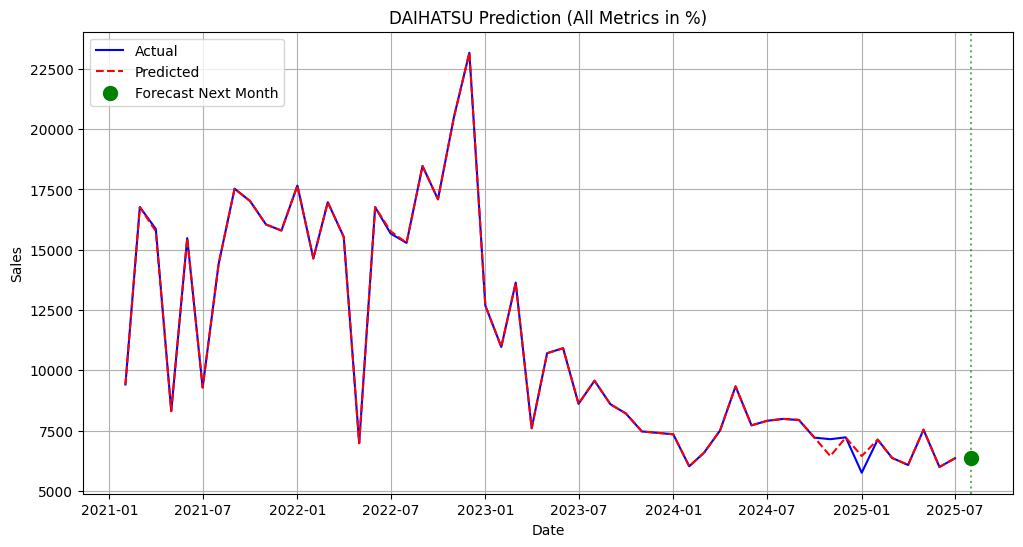


=== Forecasting untuk HONDA ===
MAE: 0.04% | RMSE: 0.05% | MAPE: 0.06% | SMAPE: 0.03% | ME: -0.00%
Prediksi HONDA untuk August 2025: 4168


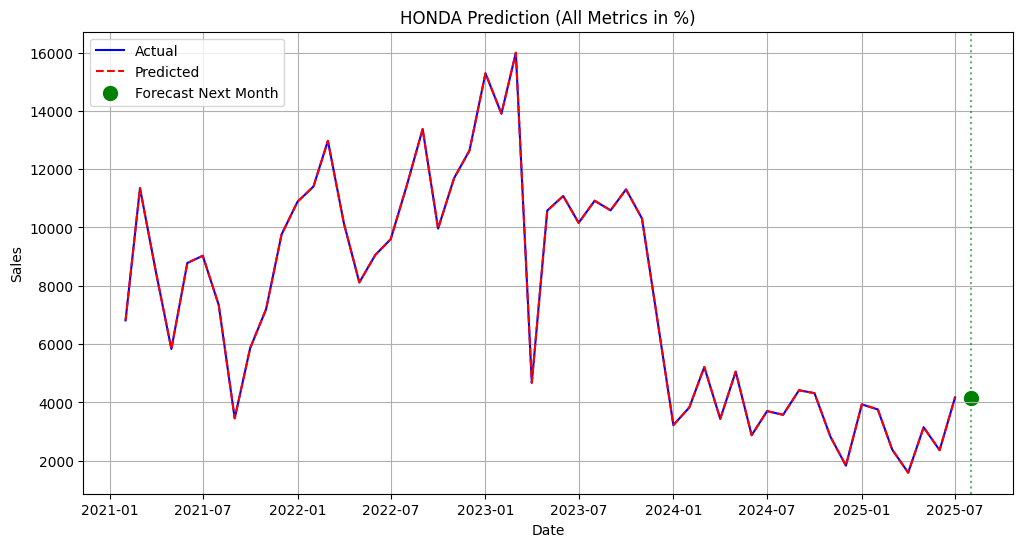


=== Forecasting untuk MITSUBISHI ===
MAE: 0.41% | RMSE: 1.45% | MAPE: 0.57% | SMAPE: 0.29% | ME: 0.01%
Prediksi MITSUBISHI untuk August 2025: 6117


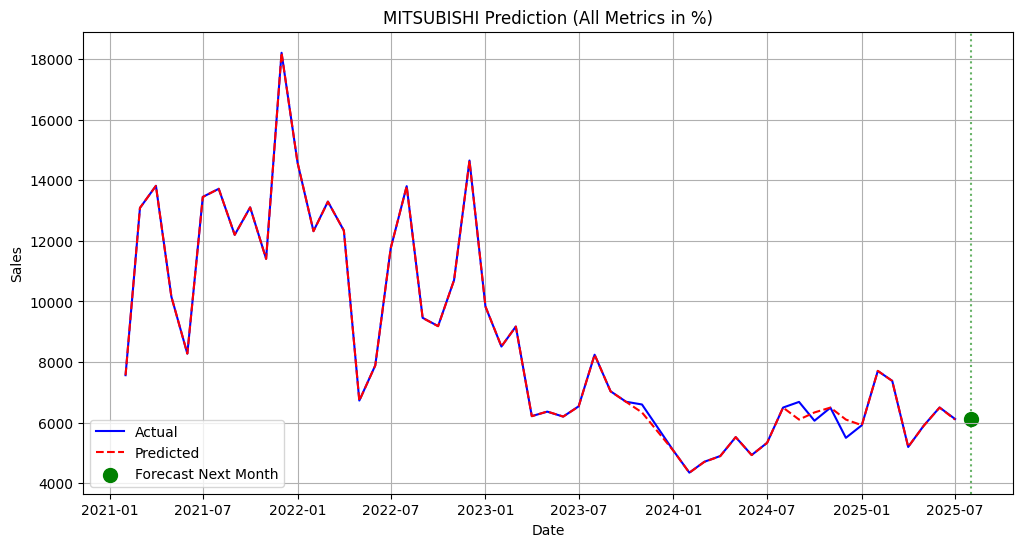


=== Forecasting untuk SUZUKI ===
MAE: 1.16% | RMSE: 5.66% | MAPE: 1.22% | SMAPE: 0.58% | ME: 0.00%
Prediksi SUZUKI untuk August 2025: 2669


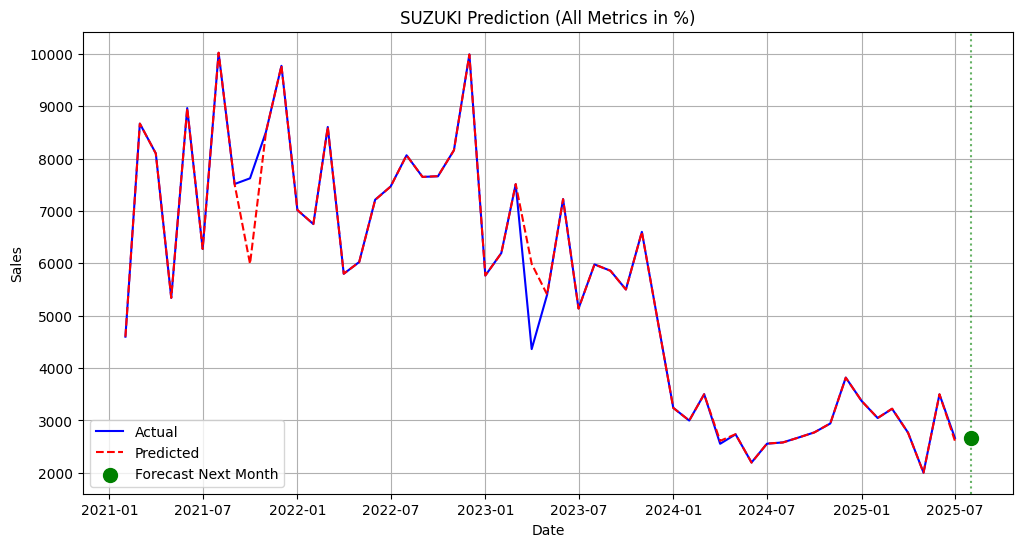


=== Forecasting untuk TOYOTA ===
MAE: 0.86% | RMSE: 4.27% | MAPE: 0.80% | SMAPE: 0.39% | ME: 0.00%
Prediksi TOYOTA untuk August 2025: 7613


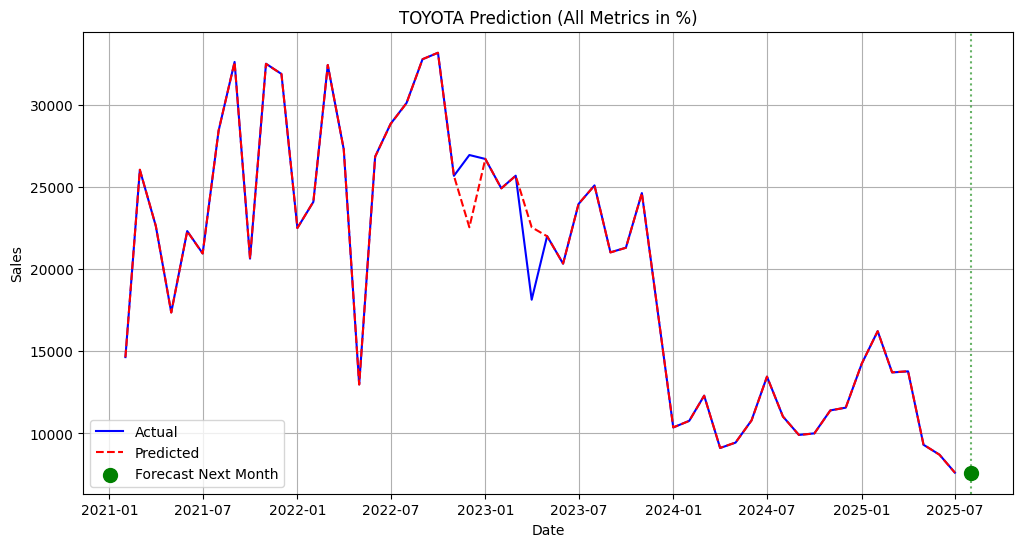

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Hasil Prediksi Penjualan Mobil Bulan Agustus:
        Brand  Sales
0    Daihatsu   6349
1       Honda   4168
2  Mitsubishi   6117
3      Suzuki   2669
4      Toyota   7613


In [8]:
# Siapkan dataframe hasil
prediksi_agustus = []

brands = ['DAIHATSU', 'HONDA', 'MITSUBISHI', 'SUZUKI', 'TOYOTA']

# Set 'waktu' column as index
df.set_index('waktu', inplace=True)

for brand in brands:
    print(f"\n=== Forecasting untuk {brand} ===")
    data = df[brand].values

    # Step 1: Universe of Discourse
    D_min, D_max = data.min(), data.max()
    buffer = (D_max - D_min) * 0.1
    U_start, U_end = D_min - buffer, D_max + buffer

    # Step 2: Partition
    num_intervals = 1400
    interval_length = (U_end - U_start) / num_intervals
    intervals = [(U_start + i * interval_length, U_start + (i + 1) * interval_length) for i in range(num_intervals)]

    # Step 3: Fuzzy sets (midpoints)
    fuzzy_sets = [np.mean(interval) for interval in intervals]

    # Step 4: Fuzzify
    def fuzzify(value, intervals):
        for i, (start, end) in enumerate(intervals):
            if start <= value <= end:
                return i
        if value < intervals[0][0]:
            return 0
        if value > intervals[-1][1]:
            return num_intervals - 1
        return None

    fuzzified_data = [fuzzify(val, intervals) for val in data]

    # Step 5 & 6: FLRs & FLRGs
    flrs = {}
    for i in range(len(fuzzified_data) - 1):
        cur, nxt = fuzzified_data[i], fuzzified_data[i + 1]
        flrs.setdefault(cur, []).append(nxt)

    flrgs = {cur: sorted(set(nexts)) for cur, nexts in flrs.items()}

    # Step 7: Forecast in-sample
    predictions = []
    for i in range(len(fuzzified_data) - 1):
        cur_state = fuzzified_data[i]
        if cur_state in flrgs:
            possible_next = flrgs[cur_state]
            pred_midpoints = [fuzzy_sets[idx] for idx in possible_next]
            predictions.append(np.mean(pred_midpoints))
        else:
            predictions.append(fuzzy_sets[cur_state])

    actual_values = data[1:]
    predicted_values = np.array(predictions)

    # Evaluasi
    min_len = min(len(actual_values), len(predicted_values))
    actual_values_eval = actual_values[:min_len]
    predicted_values_eval = predicted_values[:min_len]

    mean_actual = np.mean(actual_values_eval)

    mae = mean_absolute_error(actual_values_eval, predicted_values_eval)
    rmse = np.sqrt(mean_squared_error(actual_values_eval, predicted_values_eval))
    me = np.mean(actual_values_eval - predicted_values_eval)

    # Skala ke persen
    mae_pct = (mae / mean_actual) * 100
    rmse_pct = (rmse / mean_actual) * 100
    me_pct = (me / mean_actual) * 100

    mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) /
                          np.where(actual_values_eval != 0, actual_values_eval, 1e-8))) * 100
    smape = np.mean(np.abs(actual_values_eval - predicted_values_eval) /
                    (np.abs(actual_values_eval) + np.abs(predicted_values_eval))) * 100

    print(f"MAE: {mae_pct:.2f}% | RMSE: {rmse_pct:.2f}% | MAPE: {mape:.2f}% | "
          f"SMAPE: {smape:.2f}% | ME: {me_pct:.2f}%")

    # Prediksi bulan depan (out-of-sample)
    last_state = fuzzified_data[-1]
    if last_state in flrgs:
        possible_next = flrgs[last_state]
        pred_midpoints = [fuzzy_sets[idx] for idx in possible_next]
        next_prediction = np.mean(pred_midpoints)
    else:
        next_prediction = fuzzy_sets[last_state]

    next_date = df.index[-1] + pd.DateOffset(months=1)
    print(f"Prediksi {brand} untuk {next_date.strftime('%B %Y')}: {int(round(next_prediction))}")

    # Simpan hasil sesuai format template
    prediksi_agustus.append({
        "Brand": brand.title(),
        "Sales": int(round(next_prediction))
    })

    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(df.index[1:min_len+1], actual_values_eval, label='Actual', color='blue')
    plt.plot(df.index[1:min_len+1], predicted_values_eval, label='Predicted', color='red', linestyle='--')
    plt.scatter(next_date, next_prediction, color='green', s=100, label='Forecast Next Month')
    plt.axvline(next_date, color='green', linestyle=':', alpha=0.6)
    plt.title(f'{brand} Prediction (All Metrics in %)')
    plt.xlabel('Date')
    plt.ylabel('Sales')
    plt.legend()
    plt.grid(True)
    plt.show()

# Membuat DataFrame akhir sesuai template
final_results_df = pd.DataFrame(prediksi_agustus, columns=["Brand", "Sales"])
final_path = "theluna.csv"
final_results_df.to_csv(final_path, index=False)
files.download("theluna.csv")

print("\nHasil Prediksi Penjualan Mobil Bulan Agustus:")
print(final_results_df)
